# Explore here

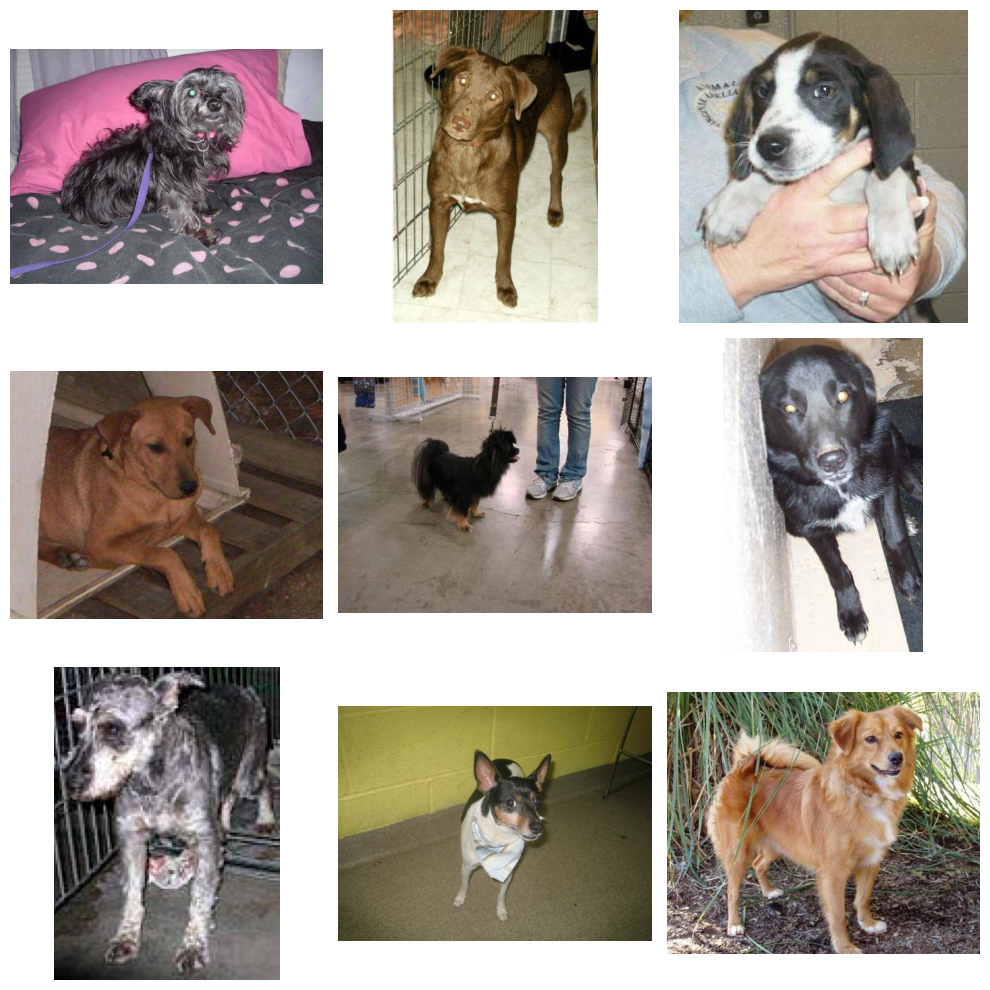

In [3]:
dog_images = sorted(glob.glob("../data/raw/dogs-vs-cats/train/dog.*.jpg"))[:9]

plt.figure(figsize=(10, 10))

for i, image_path in enumerate(dog_images):
    image = Image.open(image_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
import os
import shutil
from sklearn.model_selection import train_test_split

source = "../data/raw/dogs-vs-cats/train"
output = "../data/processed"

cats = glob.glob(source + "/cat.*.jpg")
dogs = glob.glob(source + "/dog.*.jpg")

cat_train, cat_test = train_test_split(cats, test_size=0.2, random_state=42)
dog_train, dog_test = train_test_split(dogs, test_size=0.2, random_state=42)

for split in ["train", "test"]:
    for animal in ["cats", "dogs"]:
        os.makedirs(f"{output}/{split}/{animal}", exist_ok=True)

for files, destination in [
    (cat_train, f"{output}/train/cats"),
    (cat_test, f"{output}/test/cats"),
    (dog_train, f"{output}/train/dogs"),
    (dog_test, f"{output}/test/dogs")
]:
    for file in files:
        shutil.copy2(file, destination)

print("¡Imágenes organizadas correctamente!")

¡Imágenes organizadas correctamente!


In [1]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

trdata = train_datagen.flow_from_directory(
    "../data/processed/train",
    target_size=(200, 200),
    batch_size=8,
    class_mode="categorical"
)

tsdata = test_datagen.flow_from_directory(
    "../data/processed/test",
    target_size=(200, 200),
    batch_size=8,
    class_mode="categorical",
    shuffle=False
)

I0000 00:00:1795539072.725450    1475 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795539072.740970    1475 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795539091.072497    1475 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795539104.079682    1475 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

Found 20000 images belonging to 2 classes.
Found 5000 images belonging to 2 classes.


In [2]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D

model = Sequential()

model.add(
    EfficientNetB0(
        include_top=False,
        weights=None,
        input_shape=(200, 200, 3)
    )
)

model.add(GlobalAveragePooling2D())
model.add(Dense(units=128, activation="relu"))
model.add(Dense(units=2, activation="softmax"))

model.summary()

E0000 00:00:1795536107.421167   12371 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,797 (16.07 MB)

 Trainable params: 4,171,774 (15.91 MB)

 Non-trainable params: 42,023 (164.16 KB)

In [2]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(200, 200, 3)
)

base_model.trainable = False

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dense(2, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modelo ligero preparado")

E0000 00:00:1795539192.605458    1475 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Modelo ligero preparado


In [3]:
model.save("../models/cats_dogs_model.keras")
print("Modelo guardado correctamente")

Modelo guardado correctamente


In [4]:
history = model.fit(
    trdata,
    validation_data=tsdata,
    epochs=1,
    steps_per_epoch=50,
    validation_steps=10
)

I0000 00:00:1795539275.345390    1475 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


50/50 ━━━━━━━━━━━━━━━━━━━━ 29s 406ms/step - accuracy: 0.4950 - loss: 0.7254 - val_accuracy: 1.0000 - val_loss: 0.5936


In [5]:
model.save("../models/cats_dogs_model.keras")
print("Modelo entrenado y guardado correctamente")

Modelo entrenado y guardado correctamente


In [6]:
import numpy as np

predictions = model.predict(
    tsdata,
    steps=10
)

predicted_classes = np.argmax(predictions, axis=1)

print("Primeras predicciones:")
print(predicted_classes[:20])

10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 170ms/step
Primeras predicciones:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [5]:
history = model.fit(
    trdata,
    validation_data=tsdata,
    epochs=3,
    steps_per_epoch=100,
    validation_steps=25
)

Epoch 1/3


I0000 00:00:1795537112.329627   15069 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


100/100 ━━━━━━━━━━━━━━━━━━━━ 36s 285ms/step - accuracy: 0.5163 - loss: 0.7240 - val_accuracy: 1.0000 - val_loss: 0.5045
Epoch 2/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 28s 279ms/step - accuracy: 0.4638 - loss: 0.7106 - val_accuracy: 0.0000e+00 - val_loss: 0.7622
Epoch 3/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 28s 279ms/step - accuracy: 0.4900 - loss: 0.7023 - val_accuracy: 1.0000 - val_loss: 0.6887


Bad pipe message: %s [b'B\x1c)\xe0\xe9\x8cD"+\xb3\x10\xc0\xb0\xd1\x0f\xeaP\x98\x00\x00\x84\x003\x009\x005\x00/\xc0,\xc00\x00\xa3\x00\x9f\xcc\xa9\xcc\xa8\xcc\xaa\xc0\xaf\xc0\xad\xc0\xa3\xc0\x9f\xc0+\xc0/\x00\xa2\x00\x9e\xc0\xae\xc0\xac\xc0\xa2\xc0\x9e\xc0$\xc0(\x00k\x00j\xc0s\xc0w\x00\xc4\x00\xc3\xc0#\xc0\'\x00g\x00@\xc0r\xc0v\x00\xbe\x00\xbd\xc0\n\xc0\x14\x008\x00\x88\x00\x87\xc0\t\xc0\x13\x002\x00\x9a\x00\x99\x00E\x00D\x00\x9d\xc0\xa1\xc0\x9d\x00\x9c\xc0\xa0\xc0\x9c\x00=\x00\xc0\x00<\x00\xba\x00\x84\x00\x96\x00A\x00\x07\x00\xff\x01\x00\x00F\x00\x0b\x00\x04\x03\x00\x01\x02\x00\n\x00\n\x00\x08\x00\x1d\x00\x17\x00\x19\x00\x18\x00#\x00\x00\x00\x16\x00\x00\x00\x17\x00\x00\x00\r\x00 \x00\x1e\x06\x01']
Bad pipe message: %s [b'\x06\x03\x05\x01\x05']
Bad pipe message: %s [b'\x03', b'\x04\x02\x04', b'\x01\x03', b'\x03', b'\x02', b'\x03']
Bad pipe message: %s [b'\xec\xad\xd3G\x9an\x0bU\x84\x88=]\xcc\xaa\xa1\xc9\x9b\x0b\x00\x00\x80\x00\x1d\x00\x1c\xfe\xff\xfe\xfe\x00c\x00e\x00\x11\x00r\x00\x13\x0

In [4]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modelo compilado correctamente")

Modelo compilado correctamente


In [5]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

checkpoint = ModelCheckpoint(
    "../models/best_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

print("Callbacks preparados correctamente")

Callbacks preparados correctamente


In [7]:
history = model.fit(
    trdata,
    validation_data=tsdata,
    epochs=3,
    steps_per_epoch=100,
    validation_steps=25,
    callbacks=[checkpoint, early_stopping]
)

Epoch 1/3


I0000 00:00:1795536343.259069   12371 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


: 

In [1]:
print("Todo funciona")

Todo funciona


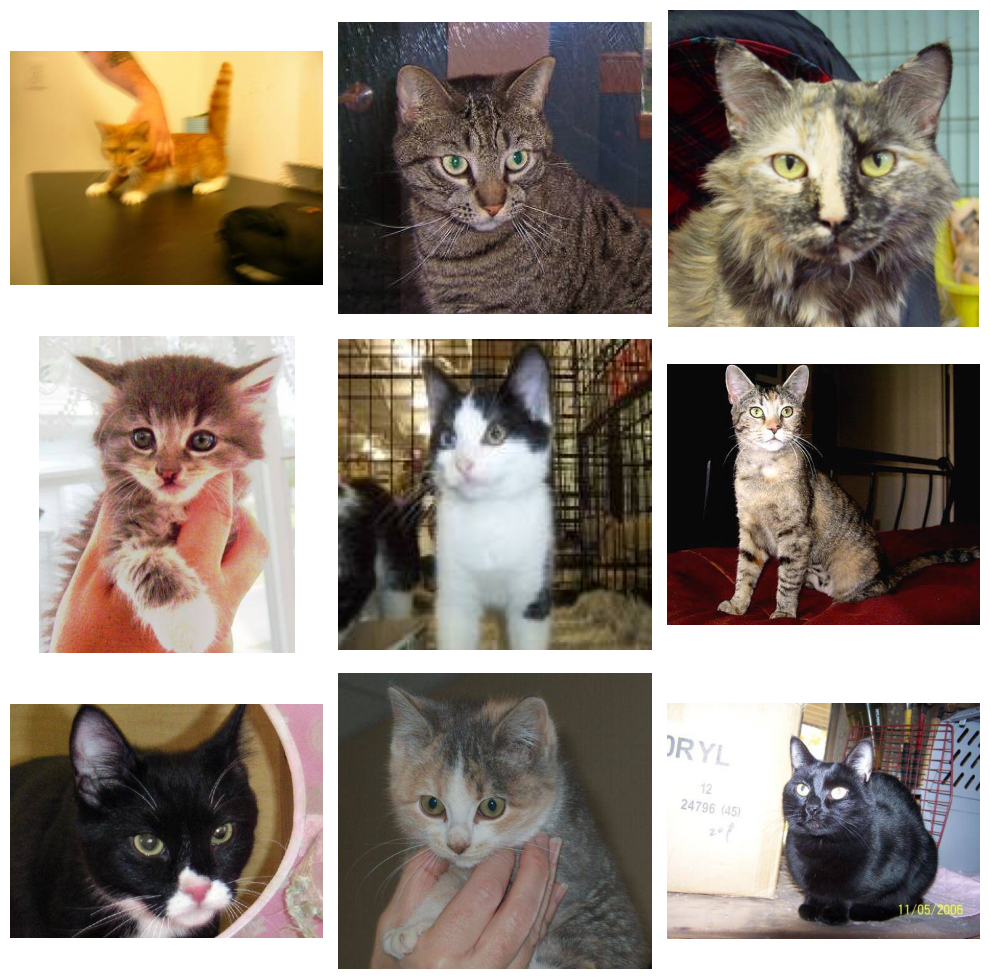

In [2]:
import glob
import matplotlib.pyplot as plt
from PIL import Image

cat_images = sorted(glob.glob("../data/raw/dogs-vs-cats/train/cat.*.jpg"))[:9]

plt.figure(figsize=(10, 10))

for i, image_path in enumerate(cat_images):
    image = Image.open(image_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.axis("off")

plt.tight_layout()
plt.show()
